# 11층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 품종별 평균 무게 — 제목이 답하는 차트 (P3 · P4)

**프롬프트**

> [역할] 너는 수산 시장 데이터 분석가야.
> [데이터] fishmarket_practice.csv — 열은 Species(품종), Weight(무게 g), Length1~3(길이 cm), Height(높이 cm), Width(두께 cm).
> [요청] 품종별 평균 무게를 막대 차트로 그려 줘. 무게가 0인 기록은 빼고, 마리 수도 함께 출력해 줘.
> [조건] 제목은 결론 문장, 축에 단위(g), 가장 큰 막대만 진하게, 그래프 글자는 영어.

전체: 159 마리 / 무게 0g 기록: 1 마리
           평균 무게(g)  마리 수
Species                  
Pike          719.0    17
Bream         618.0    35
Whitefish     531.0     6
Perch         382.0    56
Roach         160.0    19
Parkki        155.0    11
Smelt          11.0    14


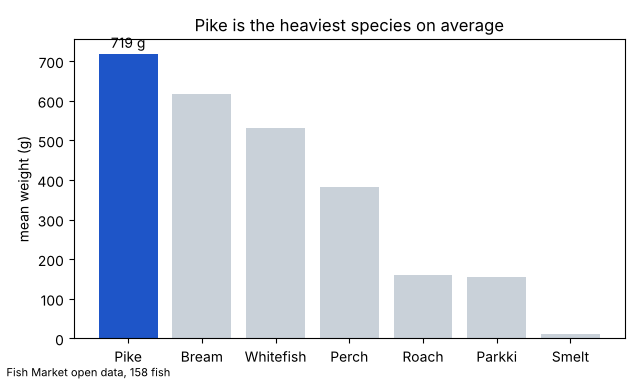

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fishmarket_practice.csv"
df = pd.read_csv(url)
print("전체:", len(df), "마리 / 무게 0g 기록:", (df["Weight"] <= 0).sum(), "마리")
df = df[df["Weight"] > 0]

m = df.groupby("Species")["Weight"].mean().sort_values(ascending=False).round(0)
print(pd.DataFrame({"평균 무게(g)": m, "마리 수": df["Species"].value_counts()}).sort_values("평균 무게(g)", ascending=False))

colors = ["#c9d1d9"] * len(m)
colors[0] = "#1e55c8"
plt.bar(m.index, m.values, color=colors)
plt.text(0, m.values[0] + 15, str(int(m.values[0])) + " g", ha="center")
plt.ylabel("mean weight (g)")
plt.title("Pike is the heaviest species on average")
plt.figtext(0.01, 0.01, "Fish Market open data, 158 fish", fontsize=8)
plt.show()

**박사의 한 줄 판단** — 1등은 강꼬치고기(평균 719g)지만 17마리뿐이고 가장 가벼운 200g부터 1,650g까지 퍼져 있습니다. 평균 하나로 “강꼬치고기는 무겁다”고 말하기 전에 마리 수와 범위를 같이 보세요. 0g 기록 한 줄을 빼는 일도 AI가 아니라 우리가 시킨 것입니다.

## 실습 2 · 나무 한 그루 vs 숲 300그루 — 학습 점수와 시험 점수

**프롬프트**

> fishmarket_practice.csv로 물고기 무게를 예측하고 싶어요.
> 특성은 Length2, Height, Width와 품종(원-핫), 75 : 25로 나눠 주세요(random_state=42).
> ① 깊이 3인 의사결정나무 ② 깊이 제한 없는 나무 ③ 나무 300그루 랜덤포레스트의
> 학습 R²·시험 R²·시험 평균 오차(g)를 표로 보여 주고, 숲의 특성 중요도를 막대로 그려 주세요(그래프 글자는 영어).

          학습 R2  시험 R2  시험 평균 오차(g)
나무 깊이 3   0.960  0.886       82.807
나무 제한 없음  1.000  0.923       58.488
숲 300그루   0.995  0.951       50.971


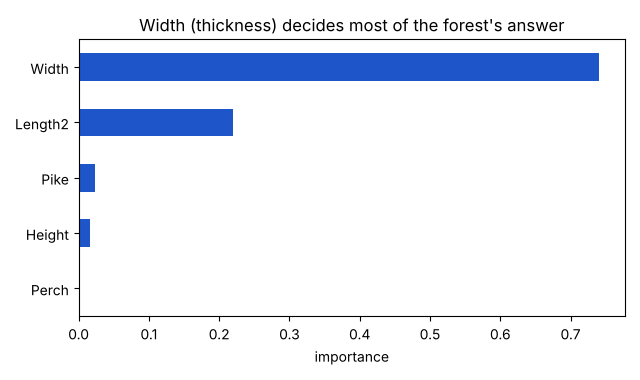

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

url = "https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fishmarket_practice.csv"
df = pd.read_csv(url)
df = df[df["Weight"] > 0]
X = pd.concat([df[["Length2", "Height", "Width"]], pd.get_dummies(df["Species"], dtype=int)], axis=1)
y = df["Weight"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

t3 = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train, y_train)
tN = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)

table = pd.DataFrame({
    "학습 R2": [t3.score(X_train, y_train), tN.score(X_train, y_train), rf.score(X_train, y_train)],
    "시험 R2": [t3.score(X_test, y_test), tN.score(X_test, y_test), rf.score(X_test, y_test)],
    "시험 평균 오차(g)": [mean_absolute_error(y_test, t3.predict(X_test)), mean_absolute_error(y_test, tN.predict(X_test)), mean_absolute_error(y_test, rf.predict(X_test))]},
    index=["나무 깊이 3", "나무 제한 없음", "숲 300그루"]).round(3)
print(table)

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(5)
imp.plot.barh(color="#1e55c8")
plt.xlabel("importance")
plt.title("Width (thickness) decides most of the forest's answer")
plt.show()

**박사의 한 줄 판단** — 제한 없는 나무는 학습 R² 1.000 — 본 물고기는 모두 맞혔지만 시험에서는 0.923입니다. 숲은 시험 0.951, 평균 오차 51g으로 가장 좋습니다. 중요도 1위가 길이가 아니라 두께(Width)라는 점은 교안의 “길이 ≥ 40cm?” 예시와 다릅니다 — 실제 데이터에게 물어봐야 아는 부분입니다.